# CNN 합성곱 신경망 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week10/cnn/lab/cnn.ipynb)

작은 필터를 그림 전체에 재사용한다. 합성곱 · 풀링을 직접 구현하고, CNN 과 완전연결을 비교한다.

- **파트 1**: 합성곱 · 최대 풀링 직접 구현 → 손글씨 7 에서 3.0, 26×26, 13×13
- **파트 2**: 출력 크기 · 가중치 수 계산 → PyTorch 와 비교
- **파트 3**: 작은 CNN vs 완전연결 (MNIST), 학습된 필터

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요. 파트 3 은 몇 분 걸린다.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torchvision import datasets

In [ ]:
tr = datasets.MNIST("data", train=True, download=True); te = datasets.MNIST("data", train=False, download=True)
img = te.data[0].numpy() / 255                            # the handwritten 7 from the slides
plt.imshow(img, cmap="gray_r"); plt.title(f"label {te.targets[0].item()}"); plt.show()

**예상 결과**

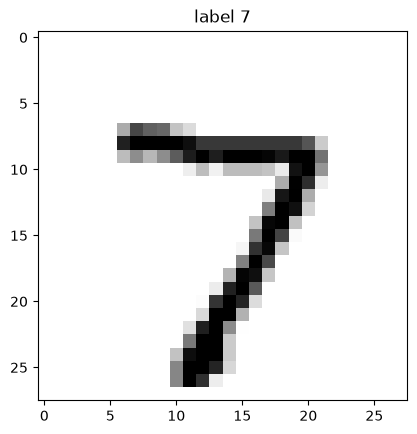

## 파트 1. 합성곱과 최대 풀링

합성곱: 3×3 창을 겹쳐 칸끼리 곱하고 더한다 (패딩 0, 보폭 1). 최대 풀링: 2×2 칸 중 가장 큰 값.

In [ ]:
def conv2d(image, kernel):
    k = kernel.shape[0]
    n = image.shape[0] - k + 1
    out = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            out[i, j] = None  # TODO: multiply the window by the kernel and sum
    return out

def max_pool(fmap, size=2):
    n = fmap.shape[0] // size
    return None  # TODO: max over each size x size block

horizontal = np.array([[1, 1, 1], [0, 0, 0], [-1, -1, -1]], dtype=float)
vertical = horizontal.T
fh = np.maximum(conv2d(img, horizontal), 0)
fv = np.maximum(conv2d(img, vertical), 0)
print("feature map:", fh.shape, " value at (8, 7):", round(fh[8, 7], 2), " max:", round(fh.max(), 2))
print("after pooling:", max_pool(fh).shape)
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, m, t in zip(axs, [fh, fv, max_pool(fh)], ["horizontal", "vertical", "pooled horizontal"]):
    ax.imshow(m, cmap="magma"); ax.set_title(t); ax.axis("off")
plt.show()

**예상 결과**

```
feature map: (26, 26)  value at (8, 7): 2.99  max: 2.99
after pooling: (13, 13)
```

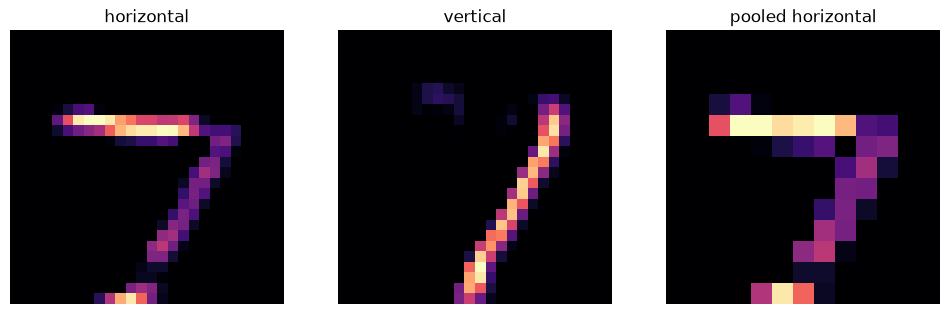

## 파트 2. 출력 크기와 가중치 수

$$\text{out} = \left\lfloor\frac{n - k + 2p}{s}\right\rfloor + 1, \qquad \text{params} = (k^2 c_{in} + 1)\,c_{out}$$

In [ ]:
def out_size(n, k, p=0, s=1):
    return None  # TODO: output size formula

def conv_params(k, c_in, c_out):
    return (k * k * c_in + 1) * c_out

for n, k, p, s in [(28, 3, 0, 1), (28, 3, 1, 1), (28, 3, 1, 2), (32, 5, 0, 1)]:
    layer = nn.Conv2d(1, 1, k, padding=p, stride=s)
    torch_out = layer(torch.zeros(1, 1, n, n)).shape[-1]
    print(f"n={n} k={k} p={p} s={s}: mine {out_size(n, k, p, s)}, PyTorch {torch_out}")

layers = [(3, 1, 4), (3, 4, 8), (3, 8, 16)]
mine = [conv_params(*l) for l in layers]
torch_counts = [sum(p.numel() for p in nn.Conv2d(ci, co, k).parameters()) for k, ci, co in layers]
print("params mine:", mine, "sum", sum(mine), "  PyTorch:", torch_counts)
print("fully connected 784 -> 1600:", 784 * 1600 + 1600, " ratio:", round((784 * 1600 + 1600) / sum(mine)))

**예상 결과**

```
n=28 k=3 p=0 s=1: mine 26, PyTorch 26
n=28 k=3 p=1 s=1: mine 28, PyTorch 28
n=28 k=3 p=1 s=2: mine 14, PyTorch 14
n=32 k=5 p=0 s=1: mine 28, PyTorch 28
params mine: [40, 296, 1168] sum 1504   PyTorch: [40, 296, 1168]
fully connected 784 -> 1600: 1256000  ratio: 835
```

## 파트 3. 작은 CNN vs 완전연결

같은 조건 (Adam, 배치 64, 2 에폭) 에서 가중치 수와 시험 정확도를 비교한다.

In [ ]:
Xtr = tr.data.float().unsqueeze(1) / 255; ytr = tr.targets
Xte = te.data.float().unsqueeze(1) / 255; yte = te.targets

def cnn():
    return nn.Sequential(nn.Conv2d(1, 8, 3), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(8, 16, 3), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Flatten(), nn.Linear(None, 10))  # TODO: size after two conv+pool blocks (28 -> 26 -> 13 -> 11 -> 5)

def mlp():
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))

def train_eval(net, epochs=2):
    opt = torch.optim.Adam(net.parameters(), 1e-3)
    for ep in range(epochs):
        for b in torch.randperm(60000, generator=torch.Generator().manual_seed(ep)).split(64):
            opt.zero_grad(); nn.functional.cross_entropy(net(Xtr[b]), ytr[b]).backward(); opt.step()
    with torch.no_grad():
        return (net(Xte).argmax(1) == yte).float().mean().item()

models = {}
for name, make in [("CNN", cnn), ("MLP", mlp)]:
    torch.manual_seed(0); net = make(); acc = train_eval(net); models[name] = net
    print(f"{name}: {sum(p.numel() for p in net.parameters()):,} params, test accuracy {acc:.3f}")

**예상 결과**

```
CNN: 5,258 params, test accuracy 0.975
MLP: 101,770 params, test accuracy 0.964
```

In [ ]:
filters = models["CNN"][0].weight.detach()[:, 0]          # 8 learned 3x3 filters
fig, axs = plt.subplots(1, 8, figsize=(14, 2))
v = filters.abs().max()
for ax, f in zip(axs, filters):
    ax.imshow(f, cmap="coolwarm", vmin=-v, vmax=v); ax.axis("off")
plt.show()

**예상 결과**

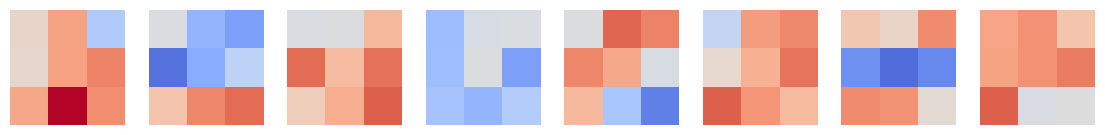

**확인 질문**
1. 파트 1 에서 가로선 필터의 값이 가장 큰 곳은 7 의 어디인가? 세로선 필터는?
2. 파트 2 에서 컬러 사진 (3채널) 을 받는 3×3 필터 64개의 가중치 수는?
3. 파트 3 의 CNN 에서 `MaxPool2d` 를 빼면 `Linear` 의 입력 크기와 가중치 수는 어떻게 되나?
4. 파트 3 의 학습된 필터 중 가로선 · 세로선 필터와 닮은 것이 있는가?

데이터 출처: LeCun, Cortes, Burges, MNIST handwritten digit database (torchvision).